# Step 4 — The four baseline policies, and how to measure honestly

We have a game. Now we need something to compare against.

Before you can claim a trained neural network is good, you have to know what **simple**
looks like. The project uses four baseline policies, and they are what every trained agent
is measured against. The `random` baseline matters most: a policy whose survival numbers
match it has learned nothing, however sophisticated the architecture.

In [1]:
N = 3
SEED = 0
EPISODES = 100_000

import numpy as np
import matplotlib.pyplot as plt

SHOOT_LEFT = 0
SHOOT_RIGHT = 1
MISS = 2

## 4.1 The game again

This is step 2's plain game, unchanged. I am using the plain version rather than the
PettingZoo one because it is faster and we are about to run it hundreds of thousands of
times, and because nothing here needs the framework.

In [2]:
class Gruel:
    def __init__(self, n=3, seating="random", seed=0):
        self.n = n
        self.seating = seating
        self.rng = np.random.default_rng(seed)
        self.stagnation_rounds = 10
        self.max_steps = 200 * n

    def reset(self):
        accuracies_ascending = []
        for k in range(self.n):
            fraction = k / (self.n - 1)
            accuracies_ascending.append(0.4 + (0.8 - 0.4) * fraction)
        accuracies_ascending = np.array(accuracies_ascending)

        if self.seating == "ranked":
            self.accuracies = accuracies_ascending.copy()
        else:
            self.accuracies = self.rng.permutation(accuracies_ascending)

        self.order = list(range(self.n))
        self.t = 0
        self.miss_streak = 0
        self.finished = False
        self.reason = None
        self.rewards = np.zeros(self.n)
        self.shots_fired = 0
        self.deliberate_misses = 0
        self.actor = int(self.rng.choice(self.order))

    def n_alive(self):
        return len(self.order)

    def neighbours(self, position):
        index_in_order = self.order.index(position)
        how_many_alive = len(self.order)
        left = self.order[(index_in_order - 1) % how_many_alive]
        right = self.order[(index_in_order + 1) % how_many_alive]
        return left, right

    def observe(self, position):
        left, right = self.neighbours(position)
        return np.array([
            self.accuracies[position],
            self.accuracies[left],
            self.accuracies[right],
            self.n_alive() / self.n,
        ])

    def step(self, action):
        shooter = self.actor
        self.t = self.t + 1

        if action == MISS:
            self.miss_streak = self.miss_streak + 1
            self.deliberate_misses = self.deliberate_misses + 1
        else:
            left, right = self.neighbours(shooter)
            if action == SHOOT_LEFT:
                target = left
            else:
                target = right

            self.miss_streak = 0
            self.shots_fired = self.shots_fired + 1

            roll = self.rng.random()
            if roll < self.accuracies[shooter]:
                self.order.remove(target)

        if self.n_alive() == 1:
            self.finished = True
            self.reason = "sole_survivor"
            self.rewards[self.order[0]] = 1.0
        elif self.miss_streak >= self.stagnation_rounds * self.n_alive():
            self.finished = True
            self.reason = "stagnation"
            share = 1.0 / self.n_alive()
            for position in self.order:
                self.rewards[position] = share
        elif self.t >= self.max_steps:
            self.finished = True
            self.reason = "hard_cap"
            share = 1.0 / self.n_alive()
            for position in self.order:
                self.rewards[position] = share

        if not self.finished:
            self.actor = int(self.rng.choice(self.order))

## 4.2 The four policies

All four see only the observation — four numbers. That restriction is deliberate: it is
the same information the trained agents will get, which is what makes the comparison
fair.

| Policy | What it does | Why it is in the set |
|---|---|---|
| `shoot_strongest` | Fire at the better shot of your two neighbours | The one the theory says is the equilibrium at N=3 |
| `shoot_weakest` | Fire at the worse shot | The obvious wrong answer. Useful precisely because it is wrong |
| `random` | Pick one of the three actions uniformly | The "learned nothing" floor |
| `always_miss` | Never fire | The other kind of nothing: everyone survives, nobody wins |

All four take `(observation, rng)` even though two of them ignore `rng`. Keeping one
signature means the measuring code doesn't need to know which policy it has.

In [3]:
def shoot_strongest(observation, rng):
    left_accuracy = observation[1]
    right_accuracy = observation[2]
    if left_accuracy > right_accuracy:
        return SHOOT_LEFT
    else:
        return SHOOT_RIGHT


def shoot_weakest(observation, rng):
    left_accuracy = observation[1]
    right_accuracy = observation[2]
    if left_accuracy < right_accuracy:
        return SHOOT_LEFT
    else:
        return SHOOT_RIGHT


def random_policy(observation, rng):
    return int(rng.integers(3))


def always_miss(observation, rng):
    return MISS


POLICIES = {
    "shoot_strongest": shoot_strongest,
    "shoot_weakest": shoot_weakest,
    "random": random_policy,
    "always_miss": always_miss,
}

## 4.3 Measuring survival by accuracy

Two things about this function are worth pausing on.

**It counts by accuracy, not by position.** Seating is reshuffled every episode, so
"position 0 won 30% of the time" means nothing. What we want is "the 0.4 player won X% of
the time", wherever they happened to be sitting.

**It adds up `rewards`, not wins.** In a stagnated episode there is no winner — three
players each get 1/3. If you counted winners you would throw those episodes away and your
probabilities would not add to 1.

In [4]:
def measure(policy, n, episodes, seed):
    """Run many episodes and return survival probability per accuracy level."""
    game = Gruel(n=n, seating="random", seed=seed)

    accuracy_levels = []
    for k in range(n):
        fraction = k / (n - 1)
        accuracy_levels.append(0.4 + (0.8 - 0.4) * fraction)
    accuracy_levels = np.array(accuracy_levels)

    total_reward_per_level = np.zeros(n)
    stagnated_episodes = 0
    capped_episodes = 0
    total_shots = 0
    total_deliberate_misses = 0

    for episode in range(episodes):
        game.reset()

        while not game.finished:
            position = game.actor
            observation = game.observe(position)
            action = policy(observation, game.rng)
            game.step(action)

        if game.reason == "stagnation":
            stagnated_episodes = stagnated_episodes + 1
        if game.reason == "hard_cap":
            capped_episodes = capped_episodes + 1

        total_shots = total_shots + game.shots_fired
        total_deliberate_misses = total_deliberate_misses + game.deliberate_misses

        for position in range(n):
            reward_here = game.rewards[position]
            if reward_here > 0:
                accuracy_here = game.accuracies[position]
                differences = np.abs(accuracy_levels - accuracy_here)
                level_index = int(np.argmin(differences))
                total_reward_per_level[level_index] += reward_here

    survival = total_reward_per_level / episodes

    total_actions = total_shots + total_deliberate_misses
    if total_actions > 0:
        miss_fraction = total_deliberate_misses / total_actions
    else:
        miss_fraction = 0.0

    results = {
        "accuracy_levels": accuracy_levels,
        "survival": survival,
        "stagnation_rate": stagnated_episodes / episodes,
        "cap_rate": capped_episodes / episodes,
        "miss_fraction": miss_fraction,
    }
    return results

## 4.4 All four, measured

In [5]:
all_results = {}

for name in POLICIES:
    policy = POLICIES[name]
    all_results[name] = measure(policy, N, EPISODES, SEED)

levels = all_results["shoot_strongest"]["accuracy_levels"]

header = "policy            " + "".join(f"  p={a:.1f}  " for a in levels)
print(header)
print("-" * len(header))
for name in POLICIES:
    survival = all_results[name]["survival"]
    row = f"{name:<18}"
    for value in survival:
        row = row + f"  {value:.4f}"
    print(row)

print()
print("policy            stagnation   deliberate misses   hard cap")
print("-" * 60)
for name in POLICIES:
    r = all_results[name]
    print(f"{name:<18}  {r['stagnation_rate']:.4f}       {r['miss_fraction']:.4f}"
          f"            {r['cap_rate']:.4f}")

policy              p=0.4    p=0.6    p=0.8  
---------------------------------------------
shoot_strongest     0.3705  0.3324  0.2971
shoot_weakest       0.0723  0.3326  0.5950
random              0.2213  0.3335  0.4452
always_miss         0.3333  0.3333  0.3333

policy            stagnation   deliberate misses   hard cap
------------------------------------------------------------
shoot_strongest     0.0000       0.0000            0.0000
shoot_weakest       0.0000       0.0000            0.0000
random              0.0000       0.3340            0.0000
always_miss         1.0000       1.0000            0.0000


## 4.5 Reading that table

Four things in it are worth saying out loud.

**`shoot_strongest` reproduces the theory.** It should be sitting on 0.370 / 0.333 / 0.296
for accuracies 0.4 / 0.6 / 0.8. Checked properly below.

**`shoot_weakest` gives a completely different profile**, and it is roughly the reverse.
When everyone hunts the weak, being weak stops being safe. So survival-of-the-weakest is
not a law of the game — it is a consequence of *how people target*.

**`random` sits in between**, and it is the number to be suspicious of. If a trained agent
lands here, it has probably learned nothing.

**`always_miss` stagnates 100% of the time** and gives everyone exactly 1/N. Nobody wins
and nobody dies.

### Two things in the numbers I did not expect

**The middle player gets 1/3 under every policy.** Look down the `p=0.6` column:
0.3324, 0.3326, 0.3335, 0.3333. Four completely different policies, and the middle
accuracy survives one third of the time in all of them. The exact answer for the middle
player is $9/27$, which *is* $1/3$. Whether that is a general fact or a coincidence of
N=3 with evenly spaced accuracies is a good question to ask, and folder 02 can answer it
by just changing the numbers and re-solving.

**`shoot_weakest` does not merely reverse the profile, it flattens the weak player.** The
0.4 player drops from 0.370 to 0.072 — a factor of five. Being the weakest is either the
best or nearly the worst position in the game, depending entirely on what everybody else
has decided to do.

## 4.6 Against the exact answer

At N=3 the exact values are known fractions. Comparing to them needs a **standard error**,
because a Monte Carlo estimate is never going to land exactly on the truth.

For a probability $p$ estimated from $M$ independent episodes,

$$\text{standard error} = \sqrt{\frac{p(1-p)}{M}}$$

At $p \approx 0.37$ and $M = 100{,}000$ that is about 0.0015. So a gap of 0.001 is nothing
and a gap of 0.01 is a bug. **Any difference smaller than about 3 standard errors is
agreement.**

In [6]:
if N == 3:
    # Weakest first, to match `levels`.
    exact = np.array([10 / 27, 9 / 27, 8 / 27])
    measured = all_results["shoot_strongest"]["survival"]
    standard_error = np.sqrt(exact * (1 - exact) / EPISODES)

    print(f"shoot_strongest, {EPISODES:,} episodes")
    print()
    print("accuracy   exact     measured   diff       s.e.      diff/s.e.")
    for i in range(3):
        difference = measured[i] - exact[i]
        print(f"  {levels[i]:.1f}      {exact[i]:.5f}   {measured[i]:.5f}   "
              f"{difference:+.5f}   {standard_error[i]:.5f}   {difference / standard_error[i]:+.2f}")

    biggest = np.max(np.abs((measured - exact) / standard_error))
    print()
    print(f"worst disagreement: {biggest:.2f} standard errors")
    if biggest < 3:
        print("=> agrees with the exact answer.")
    else:
        print("=> does NOT agree. Something is wrong.")

shoot_strongest, 100,000 episodes

accuracy   exact     measured   diff       s.e.      diff/s.e.
  0.4      0.37037   0.37053   +0.00016   0.00153   +0.10
  0.6      0.33333   0.33236   -0.00097   0.00149   -0.65
  0.8      0.29630   0.29711   +0.00081   0.00144   +0.56

worst disagreement: 0.65 standard errors
=> agrees with the exact answer.


## 4.7 A picture

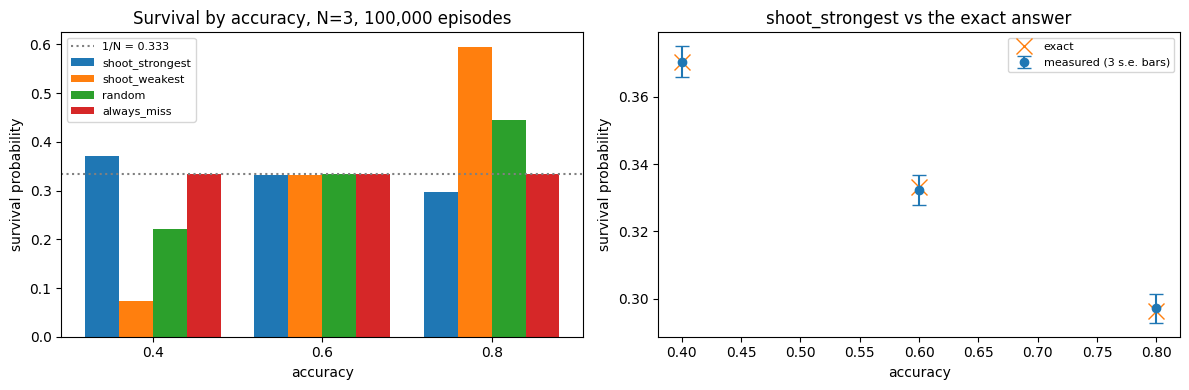

In [7]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4))

bar_width = 0.2
x_positions = np.arange(len(levels))

for index, name in enumerate(POLICIES):
    survival = all_results[name]["survival"]
    offset = (index - 1.5) * bar_width
    axes[0].bar(x_positions + offset, survival, bar_width, label=name)

axes[0].axhline(1.0 / N, color="grey", linestyle=":", label=f"1/N = {1/N:.3f}")
axes[0].set_xticks(x_positions)
axes[0].set_xticklabels([f"{a:.1f}" for a in levels])
axes[0].set_xlabel("accuracy")
axes[0].set_ylabel("survival probability")
axes[0].set_title(f"Survival by accuracy, N={N}, {EPISODES:,} episodes")
axes[0].legend(fontsize=8)

if N == 3:
    measured = all_results["shoot_strongest"]["survival"]
    exact = np.array([10 / 27, 9 / 27, 8 / 27])
    standard_error = np.sqrt(exact * (1 - exact) / EPISODES)

    axes[1].errorbar(levels, measured, yerr=3 * standard_error, fmt="o",
                     capsize=5, label="measured (3 s.e. bars)")
    axes[1].plot(levels, exact, "x", markersize=12, label="exact")
    axes[1].set_xlabel("accuracy")
    axes[1].set_ylabel("survival probability")
    axes[1].set_title("shoot_strongest vs the exact answer")
    axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 4.8 How many episodes is enough?

Worth seeing rather than being told. The standard error shrinks like $1/\sqrt{M}$, which is
slow: to halve your error bar you need **four times** the episodes.

In [8]:
for episodes in [1_000, 10_000, 100_000]:
    result = measure(shoot_strongest, 3, episodes, SEED)
    weakest = result["survival"][0]
    error = abs(weakest - 10 / 27)
    predicted_se = np.sqrt((10 / 27) * (1 - 10 / 27) / episodes)
    print(f"{episodes:>7,} episodes: weakest = {weakest:.4f}, "
          f"off by {error:.4f}, predicted s.e. {predicted_se:.4f}")

print()
print("The project uses 10,000 episodes per evaluation, giving about 0.005 of wobble.")

  1,000 episodes: weakest = 0.3840, off by 0.0136, predicted s.e. 0.0153


 10,000 episodes: weakest = 0.3756, off by 0.0052, predicted s.e. 0.0048


100,000 episodes: weakest = 0.3705, off by 0.0002, predicted s.e. 0.0015

The project uses 10,000 episodes per evaluation, giving about 0.005 of wobble.


## 4.9 Comparing policies when there are more than two players

Here is a problem that does not exist in chess. If policy A beats policy B, what does
that even mean with three players?

The project's answer is the **focal-agent protocol**: one player uses the policy being
tested, everybody else uses the baseline. Then you ask how the focal player did *at each
accuracy level*, because a policy that only wins when handed the 0.8 slot has not proven
anything.

In [9]:
def measure_focal(focal_policy, baseline_policy, n, episodes, seed):
    """One player uses focal_policy, the rest use baseline_policy."""
    game = Gruel(n=n, seating="random", seed=seed)

    accuracy_levels = []
    for k in range(n):
        fraction = k / (n - 1)
        accuracy_levels.append(0.4 + (0.8 - 0.4) * fraction)
    accuracy_levels = np.array(accuracy_levels)

    reward_when_focal = np.zeros(n)
    times_focal_had_level = np.zeros(n)

    for episode in range(episodes):
        game.reset()

        # The focal player is always position 0. Since seating is reshuffled, position 0
        # gets every accuracy level roughly equally often.
        focal_position = 0

        while not game.finished:
            position = game.actor
            observation = game.observe(position)
            if position == focal_position:
                action = focal_policy(observation, game.rng)
            else:
                action = baseline_policy(observation, game.rng)
            game.step(action)

        focal_accuracy = game.accuracies[focal_position]
        differences = np.abs(accuracy_levels - focal_accuracy)
        level_index = int(np.argmin(differences))

        times_focal_had_level[level_index] += 1
        reward_when_focal[level_index] += game.rewards[focal_position]

    survival = reward_when_focal / times_focal_had_level
    return accuracy_levels, survival


FOCAL_EPISODES = 30_000

levels_f, focal_strongest = measure_focal(shoot_strongest, shoot_strongest, N,
                                          FOCAL_EPISODES, SEED)
levels_f, focal_weakest = measure_focal(shoot_weakest, shoot_strongest, N,
                                        FOCAL_EPISODES, SEED)
levels_f, focal_miss = measure_focal(always_miss, shoot_strongest, N,
                                     FOCAL_EPISODES, SEED)

print(f"One focal player against shoot_strongest opponents, {FOCAL_EPISODES:,} episodes")
print()
print("focal plays        " + "".join(f"  p={a:.1f} " for a in levels_f))
print("-" * 50)
print("shoot_strongest    " + "".join(f"  {v:.4f}" for v in focal_strongest))
print("shoot_weakest      " + "".join(f"  {v:.4f}" for v in focal_weakest))
print("always_miss        " + "".join(f"  {v:.4f}" for v in focal_miss))
print()
print("Row 1 is the reference: everybody doing the same thing.")
print("A row above it at some accuracy means that deviation pays off there.")

One focal player against shoot_strongest opponents, 30,000 episodes

focal plays          p=0.4   p=0.6   p=0.8 
--------------------------------------------------
shoot_strongest      0.3704  0.3347  0.2953
shoot_weakest        0.3478  0.2779  0.2419
always_miss          0.0000  0.0000  0.0000

Row 1 is the reference: everybody doing the same thing.
A row above it at some accuracy means that deviation pays off there.


`always_miss` is a weak test of "fire in the air", because nobody proposes never firing at
all. The classic version is to **abstain while all three are alive and shoot once it is a
duel**, so the other two fight first. That is tested here against the same opponents.

Its effect on the weakest player is small, so this row uses ten times the episodes, and
the standard error of each cell is printed so the gap can be read against it.

In [10]:
def fire_in_air(observation, rng):
    """Abstain while every player is alive; shoot the stronger neighbour once someone has died."""
    if observation[3] > 0.99:
        return MISS
    return shoot_strongest(observation, rng)


FIRE_IN_AIR_EPISODES = 300_000
levels_f, focal_air = measure_focal(fire_in_air, shoot_strongest, N, FIRE_IN_AIR_EPISODES, SEED)
levels_f, focal_strongest_long = measure_focal(shoot_strongest, shoot_strongest, N,
                                               FIRE_IN_AIR_EPISODES, SEED)

print(f"{FIRE_IN_AIR_EPISODES:,} episodes, so about {FIRE_IN_AIR_EPISODES // N:,} at each accuracy")
print()
print("focal plays        " + "".join(f"  p={a:.1f} " for a in levels_f))
print("-" * 50)
print("shoot_strongest    " + "".join(f"  {v:.4f}" for v in focal_strongest_long))
print("fire_in_air        " + "".join(f"  {v:.4f}" for v in focal_air))
print("difference         " + "".join(f" {a - s:+.4f}" for a, s in zip(focal_air, focal_strongest_long)))
cell_se = [np.sqrt(v * (1 - v) / (FIRE_IN_AIR_EPISODES / N)) for v in focal_strongest_long]
print("s.e. of one cell   " + "".join(f"  {v:.4f}" for v in cell_se))
print()
print("fire_in_air beats shoot_strongest at some accuracy:",
      any(a > s for a, s in zip(focal_air, focal_strongest_long)))

300,000 episodes, so about 100,000 at each accuracy

focal plays          p=0.4   p=0.6   p=0.8 
--------------------------------------------------
shoot_strongest      0.3723  0.3326  0.2954
fire_in_air          0.3608  0.2009  0.0000
difference          -0.0115 -0.1316 -0.2954
s.e. of one cell     0.0015  0.0015  0.0014

fire_in_air beats shoot_strongest at some accuracy: False


Read the table carefully, because it contains the most important result in this notebook.

**No deviation beats `shoot_strongest` at any accuracy level.** Row 1 is higher than both
rows below it everywhere. So if everybody is shooting their strongest neighbour, no single
player can do better by changing their mind. That is what makes it an **equilibrium**, and
it is why the exact answer 8/27, 9/27, 10/27 is the *right* number to hold agents to
rather than just one arbitrary policy's number.

**A lone abstainer survives 0.0000 of the time.** Not "less often", essentially never.
The other two keep firing, so the abstainer is simply a target that does not shoot back.

**Firing in the air only at the start does not pay either.** For the weakest player the cost
is small, because the other two are already shooting each other and nobody is shooting it.
For the strongest it is fatal: both opponents fire at it while it holds fire.

That second line matters to the project's history. The original thesis proposal expected
the weakest player to survive by *deliberately missing* — the old "fire in the air" idea —
and set a success criterion that agents must miss on purpose at least 5% of the time. The
criterion was withdrawn, because in this version of the game the equilibrium almost never
abstains: at three players never, and folder 02 finds a single state where it does, at eight.
The two tables above are that withdrawal, measured: abstention does not pay here, either
throughout or only at the start, and survival-of-the-weakest happens anyway, through
targeting alone.

This table is how you find out whether a policy is actually an **equilibrium**. If no
single player can improve their own survival by switching to something else, nobody has a
reason to change, and that is what equilibrium means.

Folder 02 does this exactly rather than by simulation, and can therefore check *every*
possible deviation instead of the three we tried here.

## 4.10 The seeding check

In [11]:
first = measure(shoot_strongest, N, 5_000, SEED)
second = measure(shoot_strongest, N, 5_000, SEED)
different = measure(shoot_strongest, N, 5_000, SEED + 1)

print("seed 0 twice   :", np.round(first["survival"], 5), np.round(second["survival"], 5))
print("seed 1         :", np.round(different["survival"], 5))
print()
print("reproducible:", np.array_equal(first["survival"], second["survival"]))

seed 0 twice   : [0.3738 0.3302 0.296 ] [0.3738 0.3302 0.296 ]
seed 1         : [0.3798 0.331  0.2892]

reproducible: True


## What to take from step 4

- Baselines answer "is this different from doing nothing". Compare against `random` first.
- Count survival **by accuracy**, and add up **rewards** rather than wins, so stagnated
  episodes are not silently dropped.
- `shoot_strongest` reproduces 0.370 / 0.333 / 0.296. `shoot_weakest` roughly reverses it,
  so survival-of-the-weakest is caused by *targeting*, not by the rules.
- Standard error is $\sqrt{p(1-p)/M}$ and shrinks like $1/\sqrt{M}$. At 100,000 episodes it
  is about 0.0015, so differences under 0.005 are noise.
- With more than two players, "beats" needs the **focal-agent protocol**: one deviator,
  everyone else on the baseline, reported per accuracy level.

Next: `step5_render_frames.py` draws the game, and `play.py` runs it in a live window.